# Student model (with distillation) training

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import json

In [2]:
seeds = [42, 43, 44, 45, 46]
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

aug_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

In [3]:
torch.manual_seed(42)
np.random.seed(42)

data_dir = '/kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset'
teacher_path = '/kaggle/input/notebooks/d12vansh/dc-teacher-multiseed/base-effnet_model_seed42.pth'
num_classes = 7
batch_size = 32
num_epochs = 50
lr = 1e-3
scale_w = [2.0, 2.0, 2.0]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
train_full_dataset = datasets.ImageFolder(data_dir, transform=aug_transforms)
val_full_dataset = datasets.ImageFolder(data_dir, transform=data_transforms)
class_names = train_full_dataset.classes
targets = train_full_dataset.targets

train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2, random_state=42, stratify=targets
)

print(f"Training images: {len(train_idx)} | Held-out test images: {len(val_idx)}")

Training images: 2460 | Held-out test images: 616


In [5]:
class dsconv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=kernel_size, 
                                   padding=padding, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.act = nn.ReLU(inplace=True)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias = False)
        self.bn2 = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.bn1(x)
        x = self.act(x)
        x = self.pointwise(x)
        x = self.bn2(x)
        return x

class CBAM(nn.Module):
    #Channel attention (avg + max, shared MLP), spatial attention (7x7 conv)
    def __init__(self, channels, reduction=8, kernel_size=7):
        super().__init__()
        reduced = max(4, channels // reduction)
        self.mlp = nn.Sequential(
            nn.Linear(channels, reduced, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(reduced, channels, bias=False)
        )
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        b, c, _, _ = x.size()
        keep = x
        avg = self.mlp(x.mean(dim=(2, 3)))
        mx = self.mlp(x.amax(dim=(2, 3)))
        x = x * torch.sigmoid(avg + mx).view(b, c, 1, 1)                  
        s = torch.cat([x.mean(dim=1, keepdim=True),
                       x.amax(dim=1, keepdim=True)], dim=1)               
        return x * torch.sigmoid(self.spatial(s)) + keep                      

class StdConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Conv2d(in_c, out_c, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_c)
    def forward(self, x):
        return self.bn(self.conv(x))

class CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.conv1 = StdConv(3, 16)
        self.relu1 = nn.ReLU()
        self.attention1 = CBAM(16)
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = dsconv(16, 32)
        self.relu2 = nn.ReLU()
        self.attention2 = CBAM(32)
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = dsconv(32, 64)
        self.relu3 = nn.ReLU()
        self.attention3 = CBAM(64)
        self.pool3 = nn.MaxPool2d(2)

        self.conv4 = dsconv(64, 128)
        self.relu4 = nn.ReLU()
        self.attention4 = CBAM(128)
        self.pool4 = nn.MaxPool2d(2)

        self.conv5 = dsconv(128, 256)
        self.relu5 = nn.ReLU()
        self.attention5 = CBAM(256)
        self.pool5 = nn.MaxPool2d(2)

        self.conv6 = dsconv(256, 512)
        self.relu6 = nn.ReLU()
       
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(64 + 128 + 256 + 512, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, return_feat=False):
        x = self.pool1(self.attention1(self.relu1(self.conv1(x))))
        x = self.pool2(self.attention2(self.relu2(self.conv2(x))))
        f3 = self.pool3(self.attention3(self.relu3(self.conv3(x))))
        f4 = self.pool4(self.attention4(self.relu4(self.conv4(f3))))  
        f5 = self.pool5(self.attention5(self.relu5(self.conv5(f4))))   
        f6 = self.relu6(self.conv6(f5))                                

        fused  = torch.cat([f.mean(dim=(2, 3)) for f in (f3, f4, f5, f6)], dim=1)
        logits = self.classifier(fused)
        return (logits, [f3, f4, f6]) if return_feat else logits

def make_sampler(labels, num_classes=7):

    class_sample_count = np.bincount(labels, minlength=num_classes)
    weights = 1.0 / np.sqrt(class_sample_count)
    samples_weight = [weights[label] for label in labels]
    return WeightedRandomSampler(weights=samples_weight, num_samples=len(samples_weight), replacement=True)

cnn = CNN(7).to(device)
cnn_params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(f"Parameters in CNN- {cnn_params:,}\n")

class EfficientNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.base_model = models.efficientnet_b0(weights=None)
        in_features = self.base_model.classifier[1].in_features
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(p=0.3, inplace=True),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.base_model(x)

Parameters in CNN- 266,833



In [6]:
effnet = EfficientNet(num_classes=num_classes).to(device)
effnet.load_state_dict(torch.load(teacher_path, map_location=device, weights_only=True))
effnet.eval()

effnet_params = sum(p.numel() for p in effnet.parameters())
print(f"Parameters in Effnet Teacher: {effnet_params:,}\n")

teacher_taps = (3, 5, 8)   # 28x28, 14x14, 7x7

@torch.no_grad()
def teacher_forward(x):
    feats = []
    for i, blk in enumerate(effnet.base_model.features):
        x = blk(x)
        if i in teacher_taps:
            feats.append(x)
    return feats

Parameters in Effnet Teacher: 4,016,515



In [7]:
train_dataset = Subset(train_full_dataset, train_idx)
test_dataset = Subset(val_full_dataset, val_idx)
train_labels = [targets[i] for i in train_idx]

def multiscale_feat_loss(s_feats, t_feats, projectors, scale_w):  
    loss = 0.0
    for proj, w, s, t in zip(projectors, scale_w, s_feats, t_feats):
        p = F.normalize(proj(s), p=2, dim=1)
        t = F.normalize(t, p=2, dim=1)
        loss = loss + w * (1.0 - (p * t).sum(dim=1)).mean()
    return loss

results = {}

for seed in seeds:
    torch.manual_seed(seed)

    sampler = make_sampler(train_labels, num_classes)

    dataloaders = {
        'Train': DataLoader(train_dataset, batch_size=batch_size, sampler=sampler),
        'Valid': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    }

    cnn = CNN(num_classes).to(device)

    projectors = nn.ModuleList([
        nn.Conv2d(64,40,1, bias=False),
        nn.Conv2d(128,112,1, bias=False),
        nn.Conv2d(512,1280,1, bias=False),
    ]).to(device)

    optimizer = torch.optim.AdamW(list(cnn.parameters()) + list(projectors.parameters()),
                                  lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    best_val_acc = 0.0
    cnn_path = f'best_student_model_{seed}.pth'
    ce_losses, feat_losses, val_accs = [], [], []

    for epoch in range(num_epochs):
        cnn.train()
        total_ce, total_feat, correct, total = 0, 0, 0, 0

        for inputs, labels in dataloaders['Train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            t_feats = teacher_forward(inputs)

            student_logits, s_feats = cnn(inputs, return_feat=True)
            ce_loss = F.cross_entropy(student_logits, labels)
            feat_loss = multiscale_feat_loss(s_feats, t_feats, projectors, scale_w)

            loss = ce_loss + feat_loss
            loss.backward()
            optimizer.step()

            total_ce += ce_loss.item() * inputs.size(0)
            total_feat += feat_loss.item() * inputs.size(0)
            preds = student_logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        scheduler.step()
        train_ce = total_ce / total
        train_feat = total_feat / total
        train_acc = correct / total

        cnn.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for val_inputs, val_labels in dataloaders['Valid']:
                val_inputs, val_labels = val_inputs.to(device), val_labels.to(device)
                val_preds = cnn(val_inputs).argmax(dim=1)
                val_correct += (val_preds == val_labels).sum().item()
                val_total += val_labels.size(0)

        val_acc = val_correct / val_total
        ce_losses.append(train_ce)
        feat_losses.append(train_feat)
        val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(cnn.state_dict(), cnn_path)
        if (epoch + 1) % 10 == 0:
            print(f"seed {seed} | epoch {epoch + 1}: ce = {train_ce:.4f} | feat = {train_feat:.4f} | train_acc = {train_acc:.4f} | holdout_acc = {val_acc:.4f}")

    results[seed] = dict(best=best_val_acc, last=val_acc, ce_loss=ce_losses, feat_loss=feat_losses, val_acc=val_accs)
    print(f"seed {seed}: best {best_val_acc:.4f} | last {val_acc:.4f}\n")

seed 42 | epoch 10: ce = 0.8970 | feat = 3.1047 | train_acc = 0.6537 | holdout_acc = 0.6802
seed 42 | epoch 20: ce = 0.6191 | feat = 2.9216 | train_acc = 0.7671 | holdout_acc = 0.7045
seed 42 | epoch 30: ce = 0.4682 | feat = 2.8340 | train_acc = 0.8325 | holdout_acc = 0.7744
seed 42 | epoch 40: ce = 0.4008 | feat = 2.7952 | train_acc = 0.8496 | holdout_acc = 0.7890
seed 42 | epoch 50: ce = 0.3673 | feat = 2.7802 | train_acc = 0.8728 | holdout_acc = 0.7987
seed 42: best 0.8101 | last 0.7987

seed 43 | epoch 10: ce = 0.8996 | feat = 3.1028 | train_acc = 0.6533 | holdout_acc = 0.6234
seed 43 | epoch 20: ce = 0.6374 | feat = 2.9222 | train_acc = 0.7671 | holdout_acc = 0.6786
seed 43 | epoch 30: ce = 0.4848 | feat = 2.8342 | train_acc = 0.8224 | holdout_acc = 0.7468
seed 43 | epoch 40: ce = 0.4185 | feat = 2.7921 | train_acc = 0.8492 | holdout_acc = 0.7808
seed 43 | epoch 50: ce = 0.3651 | feat = 2.7879 | train_acc = 0.8748 | holdout_acc = 0.7873
seed 43: best 0.7890 | last 0.7873

seed 44 


Classification Report (616 Images):
              precision    recall  f1-score   support

    Bacteria     0.9083    0.9561    0.9316       114
       Fungi     0.7806    0.8067    0.7934       150
     Healthy     0.7500    0.7500    0.7500        40
    Nematode     0.8000    0.8571    0.8276        14
        Pest     0.7600    0.6230    0.6847       122
 Phytopthora     0.8833    0.7681    0.8217        69
       Virus     0.7778    0.9159    0.8412       107

    accuracy                         0.8101       616
   macro avg     0.8086    0.8110    0.8072       616
weighted avg     0.8096    0.8101    0.8069       616



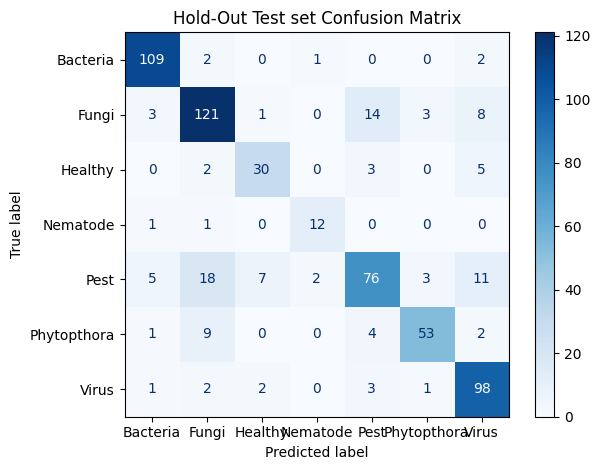

In [8]:
cnn_path = 'best_student_model_42.pth'

cnn.load_state_dict(torch.load(cnn_path, map_location=device, weights_only=True))
cnn.eval()

all_y_true, all_y_pred = [], []
with torch.no_grad():
    for val_inputs, val_labels in dataloaders['Valid']:
        val_inputs = val_inputs.to(device)
        val_preds = cnn(val_inputs).argmax(dim=1)
        all_y_true.extend(val_labels.tolist())
        all_y_pred.extend(val_preds.cpu().tolist())

print("\nClassification Report (616 Images):")
print(classification_report(all_y_true, all_y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(all_y_true, all_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Hold-Out Test set Confusion Matrix")
plt.tight_layout()
plt.savefig("student_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
with open("distill_results.json", "w") as f:
    json.dump(results, f, indent=2)

best = np.array([results[s]["best"] for s in seeds]) * 100
last = np.array([results[s]["last"] for s in seeds]) * 100

for s, b, l in zip(seeds, best, last):
    print(f"seed {s} | best: {b:.2f}% | last: {l:.2f}%")
print(f"mean   | best: {best.mean():.2f} +/- {best.std(ddof=1):.2f}% | last: {last.mean():.2f} +/- {last.std(ddof=1):.2f}%")

seed 42 | best: 81.01% | last: 79.87%
seed 43 | best: 78.90% | last: 78.73%
seed 44 | best: 81.49% | last: 81.49%
seed 45 | best: 83.28% | last: 83.28%
seed 46 | best: 81.17% | last: 80.36%
mean   | best: 81.17 +/- 1.56% | last: 80.75 +/- 1.73%


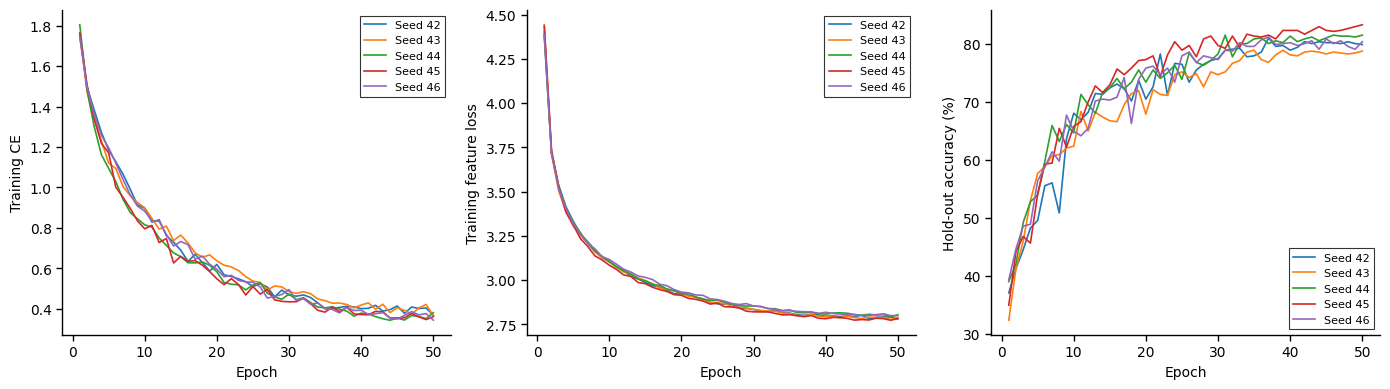

In [10]:
epochs = np.arange(1, num_epochs + 1)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))

for s in seeds:
    ax1.plot(epochs, results[s]["ce_loss"], lw=1.2, label=f"Seed {s}")
    ax2.plot(epochs, results[s]["feat_loss"], lw=1.2, label=f"Seed {s}")
    ax3.plot(epochs, np.array(results[s]["val_acc"]) * 100, lw=1.2, label=f"Seed {s}")

ax1.set_ylabel("Training CE")
ax2.set_ylabel("Training feature loss")
ax3.set_ylabel("Hold-out accuracy (%)")

for ax, loc in ((ax1, "upper right"), (ax2, "upper right"), (ax3, "lower right")):
    ax.set_xlabel("Epoch")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.tick_params(direction="out", which="major", length=4, width=1.0)
    ax.minorticks_off()
    leg = ax.legend(loc=loc, frameon=True, fancybox=False, edgecolor="black", fontsize=8)
    leg.get_frame().set_linewidth(0.8)

fig.tight_layout()
fig.savefig("student_curves.png", dpi=300, bbox_inches="tight")
plt.show()